In [43]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [44]:
df = pd.read_csv(r"C:\Users\User\Downloads\archive (4)\housing.csv")
df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [45]:
df.shape

(20640, 10)

In [46]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


In [47]:
df.isnull().sum()

longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

In [48]:
df['total_bedrooms'] = df['total_bedrooms'].fillna(
    df['total_bedrooms'].median()
)

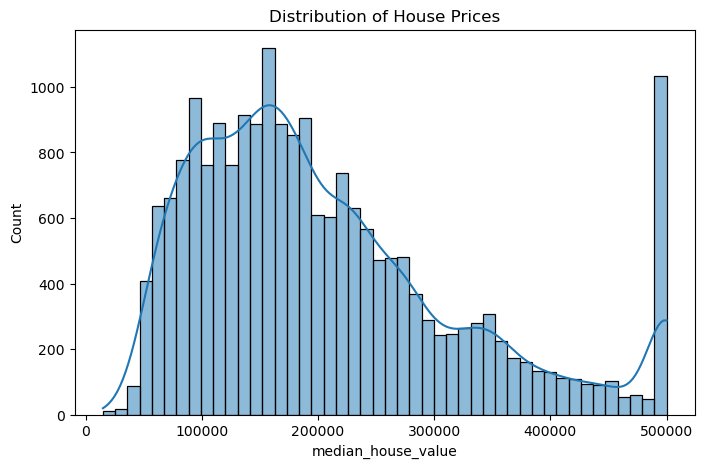

In [49]:
plt.figure(figsize=(8,5))

sns.histplot(
    df['median_house_value'],
    kde=True
)

plt.title('Distribution of House Prices')
plt.show()

In [50]:
df["median_house_value"].skew()

0.9777632739098341

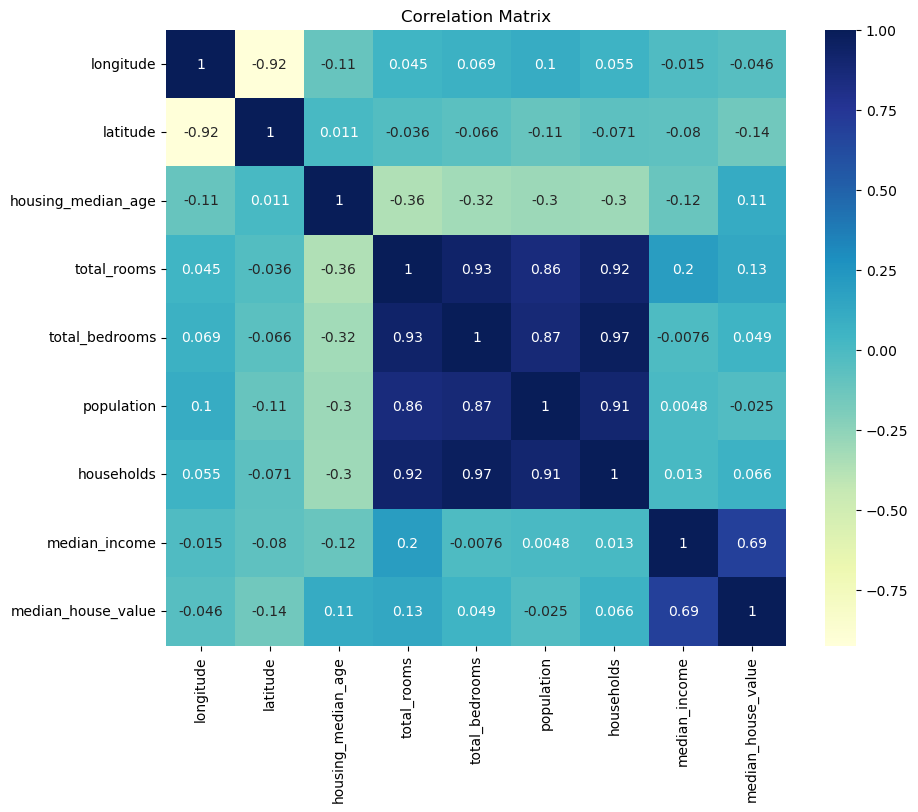

In [51]:
plt.figure(figsize=(10,8))

sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap='YlGnBu'
)

plt.title('Correlation Matrix')
plt.show()

In [52]:
df = pd.get_dummies(
    df,
    columns=['ocean_proximity'],
    drop_first=True
)

In [53]:
dummy_cols = [col for col in df.columns if 'ocean_proximity_' in col]

df[dummy_cols] = df[dummy_cols].astype(int)


In [54]:
df

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity_INLAND,ocean_proximity_ISLAND,ocean_proximity_NEAR BAY,ocean_proximity_NEAR OCEAN
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,0,0,1,0
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,0,0,1,0
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,0,0,1,0
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,0,0,1,0
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
20635,-121.09,39.48,25.0,1665.0,374.0,845.0,330.0,1.5603,78100.0,1,0,0,0
20636,-121.21,39.49,18.0,697.0,150.0,356.0,114.0,2.5568,77100.0,1,0,0,0
20637,-121.22,39.43,17.0,2254.0,485.0,1007.0,433.0,1.7000,92300.0,1,0,0,0
20638,-121.32,39.43,18.0,1860.0,409.0,741.0,349.0,1.8672,84700.0,1,0,0,0


In [55]:
y = df['median_house_value']
y

0        452600.0
1        358500.0
2        352100.0
3        341300.0
4        342200.0
           ...   
20635     78100.0
20636     77100.0
20637     92300.0
20638     84700.0
20639     89400.0
Name: median_house_value, Length: 20640, dtype: float64

In [56]:
X = df.drop(
    'median_house_value',
    axis=1
)

X

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,ocean_proximity_INLAND,ocean_proximity_ISLAND,ocean_proximity_NEAR BAY,ocean_proximity_NEAR OCEAN
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,0,0,1,0
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,0,0,1,0
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,0,0,1,0
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,0,0,1,0
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...
20635,-121.09,39.48,25.0,1665.0,374.0,845.0,330.0,1.5603,1,0,0,0
20636,-121.21,39.49,18.0,697.0,150.0,356.0,114.0,2.5568,1,0,0,0
20637,-121.22,39.43,17.0,2254.0,485.0,1007.0,433.0,1.7000,1,0,0,0
20638,-121.32,39.43,18.0,1860.0,409.0,741.0,349.0,1.8672,1,0,0,0


In [57]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [58]:
X_train
y_train

14196    103000.0
8267     382100.0
17445    172600.0
14265     93400.0
2271      96500.0
           ...   
11284    229200.0
11964     97800.0
5390     222100.0
860      283500.0
15795    325000.0
Name: median_house_value, Length: 16512, dtype: float64

In [59]:
model = LinearRegression()

model.fit(
    X_train,
    y_train
)

LinearRegression()

In [60]:
predictions = model.predict(X_test)
predictions

array([ 54055.44889898, 124225.33893718, 255489.37949165, ...,
       439180.98341181, 120797.55240621, 183386.04993584])

In [61]:
results = pd.DataFrame({
    'Actual': y_test,
    'Predicted': predictions
})

results['Difference'] = results['Actual'] - results['Predicted']

results.head(10)

,Actual,Predicted,Difference
20046,47700.0,54055.448899,-6355.448899
3024,45800.0,124225.338937,-78425.338937
15663,500001.0,255489.379492,244511.620508
20484,218600.0,268002.431569,-49402.431569
9814,278000.0,262769.434816,15230.565184
13311,158700.0,139606.303956,19093.696044
7113,198200.0,290665.423914,-92465.423914
7668,157500.0,228264.876375,-70764.876375
18246,340000.0,256506.785610,83493.214390
5723,446600.0,407923.858435,38676.141565


In [62]:
mae = mean_absolute_error(
    y_test,
    predictions
)

print(mae)

50670.73824097224


In [63]:
(mae / y_test.mean()) * 100

24.6572564008889

In [64]:
rmse = np.sqrt(
    mean_squared_error(
        y_test,
        predictions
    )
)

print(rmse)

70060.52184473515


In [65]:
from sklearn.metrics import r2_score

r2 = r2_score(y_test, predictions)

print(r2)

0.6254240620553609


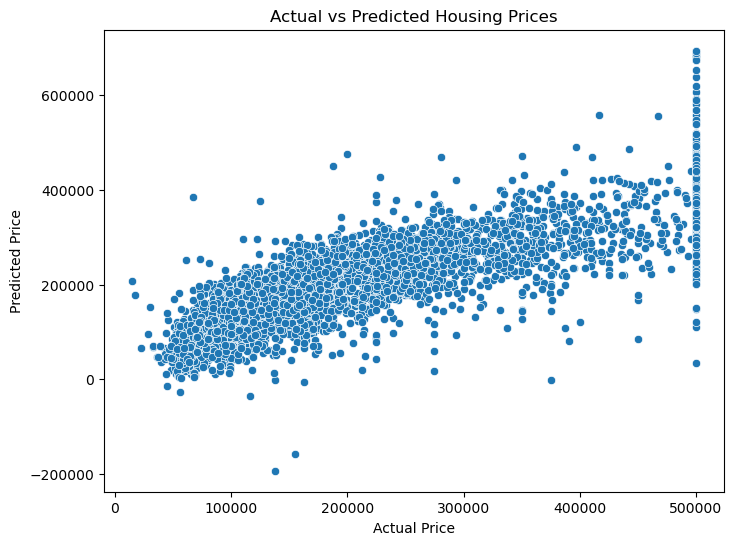

In [66]:
plt.figure(figsize=(8,6))

sns.scatterplot(
    x=y_test,
    y=predictions
)

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")

plt.title("Actual vs Predicted Housing Prices")

plt.show()

In [67]:
coefficients = pd.DataFrame(
    {
        'Feature':X.columns,
        'Coefficient':model.coef_
    }
)

coefficients.sort_values(
    by='Coefficient',
    ascending=False
)

,Feature,Coefficient
9,ocean_proximity_ISLAND,136125.072615
7,median_income,39473.975175
11,ocean_proximity_NEAR OCEAN,3431.140073
2,housing_median_age,1102.185084
4,total_bedrooms,102.789395
6,households,48.252753
3,total_rooms,-6.021506
5,population,-38.172906
10,ocean_proximity_NEAR BAY,-5136.642217
1,latitude,-25468.352050


In [68]:
print(X_train.columns)

Index(['longitude', 'latitude', 'housing_median_age', 'total_rooms',
       'total_bedrooms', 'population', 'households', 'median_income',
       'ocean_proximity_INLAND', 'ocean_proximity_ISLAND',
       'ocean_proximity_NEAR BAY', 'ocean_proximity_NEAR OCEAN'],
      dtype='object')


In [69]:
print(X.columns)

Index(['longitude', 'latitude', 'housing_median_age', 'total_rooms',
       'total_bedrooms', 'population', 'households', 'median_income',
       'ocean_proximity_INLAND', 'ocean_proximity_ISLAND',
       'ocean_proximity_NEAR BAY', 'ocean_proximity_NEAR OCEAN'],
      dtype='object')


In [70]:
new_house = pd.DataFrame({
    'longitude': [-122.25],
    'latitude': [37.85],
    'housing_median_age': [40],
    'total_rooms': [1500],
    'total_bedrooms': [250],
    'population': [600],
    'households': [240],
    'median_income': [7.2],
    'ocean_proximity_INLAND': [0],
    'ocean_proximity_ISLAND': [0],
    'ocean_proximity_NEAR BAY': [1],
    'ocean_proximity_NEAR OCEAN': [0]
})

In [71]:
predicted_price = model.predict(new_house)

print(f"Predicted House Price: ${predicted_price[0]:,.2f}")

Predicted House Price: $369,959.80


In [72]:
df["rooms_per_household"] = df["total_rooms"] / df["households"]

df["bedrooms_per_room"] = df["total_bedrooms"] / df["total_rooms"]

df["population_per_household"] = df["population"] / df["households"]

In [73]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [74]:
model = LinearRegression()

model.fit(X_train_scaled, y_train)

LinearRegression()

In [75]:
from sklearn.tree import DecisionTreeRegressor

model = DecisionTreeRegressor(
    random_state=42
)

In [76]:
from sklearn.ensemble import RandomForestRegressor

model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

model.fit(X_train, y_train)

RandomForestRegressor(random_state=42)

In [77]:
predictions = model.predict(X_test)

print(model.score(X_test, y_test))

0.8164888965922015


<Axes: xlabel='median_house_value'>

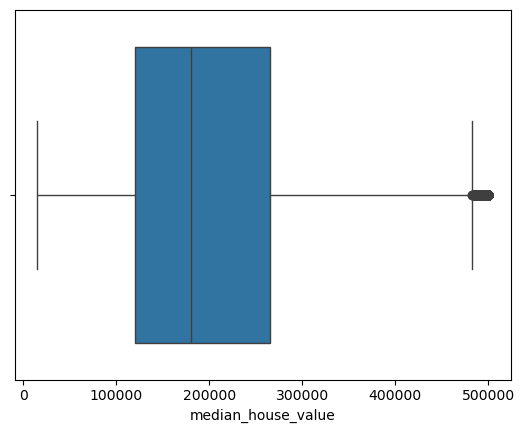

In [78]:
sns.boxplot(x=df["median_house_value"])

<Axes: xlabel='median_income'>

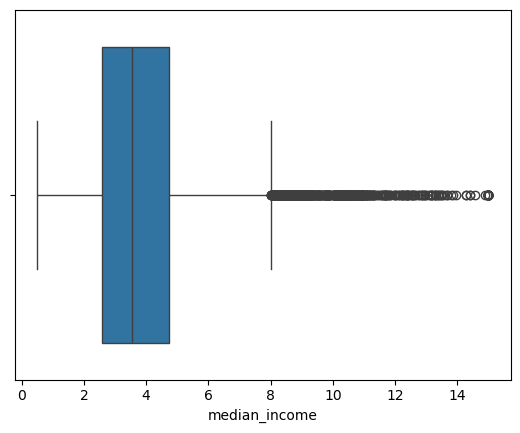

In [79]:
sns.boxplot(x=df["median_income"])

In [80]:
import numpy as np

y = np.log1p(df["median_house_value"])

In [81]:
results = pd.DataFrame({
    "Model": ["Linear Regression"],
    "R2": [r2]
})

results

,Model,R2
0,Linear Regression,0.625424


In [82]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import r2_score

dt_model = DecisionTreeRegressor(random_state=42)

dt_model.fit(X_train, y_train)

dt_predictions = dt_model.predict(X_test)

dt_r2 = r2_score(y_test, dt_predictions)

print(dt_r2)

0.6286755571919975


In [83]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

rf_predictions = rf_model.predict(X_test)

rf_r2 = r2_score(y_test, rf_predictions)

print(rf_r2)

0.8164888965922015


In [84]:
results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "R2": [
        r2,
        dt_r2,
        rf_r2
    ]
})

results.sort_values(
    by="R2",
    ascending=False
)

,Model,R2
2,Random Forest,0.816489
1,Decision Tree,0.628676
0,Linear Regression,0.625424


In [85]:
X = df.drop('median_house_value', axis=1)
y = df['median_house_value']

In [86]:
dummy_cols = [col for col in df.columns if 'ocean_proximity_' in col]

df[dummy_cols] = df[dummy_cols].astype(int)

df

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity_INLAND,ocean_proximity_ISLAND,ocean_proximity_NEAR BAY,ocean_proximity_NEAR OCEAN,rooms_per_household,bedrooms_per_room,population_per_household
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,0,0,1,0,6.984127,0.146591,2.555556
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,0,0,1,0,6.238137,0.155797,2.109842
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,0,0,1,0,8.288136,0.129516,2.802260
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,0,0,1,0,5.817352,0.184458,2.547945
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,0,0,1,0,6.281853,0.172096,2.181467
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20635,-121.09,39.48,25.0,1665.0,374.0,845.0,330.0,1.5603,78100.0,1,0,0,0,5.045455,0.224625,2.560606
20636,-121.21,39.49,18.0,697.0,150.0,356.0,114.0,2.5568,77100.0,1,0,0,0,6.114035,0.215208,3.122807
20637,-121.22,39.43,17.0,2254.0,485.0,1007.0,433.0,1.7000,92300.0,1,0,0,0,5.205543,0.215173,2.325635
20638,-121.32,39.43,18.0,1860.0,409.0,741.0,349.0,1.8672,84700.0,1,0,0,0,5.329513,0.219892,2.123209


In [87]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

RandomForestRegressor(random_state=42)

In [88]:
rf_predictions = rf_model.predict(X_test)

print(rf_predictions[:5])

[ 51521.   69669.  466710.4 247533.  268110. ]


In [89]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

mae = mean_absolute_error(y_test, rf_predictions)

rmse = mean_squared_error(
    y_test,
    rf_predictions
) ** 0.5

r2 = r2_score(
    y_test,
    rf_predictions
)

print("MAE :", mae)
print("RMSE:", rmse)
print("R2  :", r2)

MAE : 31639.373406007748
RMSE: 49038.20933848149
R2  : 0.8164888965922015


In [90]:
comparison = pd.DataFrame({
    'Model': [
        'Linear Regression',
        'Random Forest'
    ],
    'R2': [
        0.6254,      # your Linear Regression score
        r2
    ]
})

comparison

,Model,R2
0,Linear Regression,0.625400
1,Random Forest,0.816489


In [91]:
importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': rf_model.feature_importances_
})

importance.sort_values(
    by='Importance',
    ascending=False
)

,Feature,Importance
7,median_income,0.490717
8,ocean_proximity_INLAND,0.140933
0,longitude,0.106093
1,latitude,0.101897
2,housing_median_age,0.052065
5,population,0.032511
4,total_bedrooms,0.023960
3,total_rooms,0.023412
6,households,0.018376
11,ocean_proximity_NEAR OCEAN,0.008793


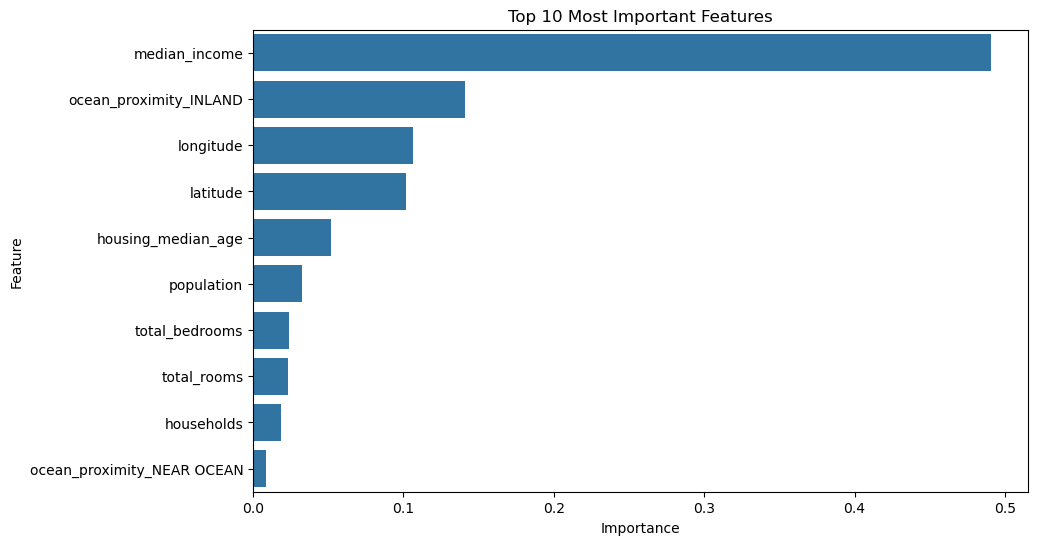

In [92]:
import seaborn as sns
import matplotlib.pyplot as plt

importance = importance.sort_values(
    by='Importance',
    ascending=False
)

plt.figure(figsize=(10,6))

sns.barplot(
    data=importance.head(10),
    x='Importance',
    y='Feature'
)

plt.title('Top 10 Most Important Features')
plt.show()

In [93]:
rf_price = rf_model.predict(new_house)

print(rf_price)
print(type(rf_price))

[376387.04]
<class 'numpy.ndarray'>


In [94]:
print(f"Predicted Price: ${rf_price[0]:,.2f}")

Predicted Price: $376,387.04
